# 00 — Combined Clean Dataset Sample Waveforms (`[11, 13, 19, 92, 42]` per Source)

Visual inspection of preprocessed 12-lead recordings (`500 Hz`, `10 s`, bandpass + `50/60 Hz` notch + Savitzky-Golay smoothed) at local indices **`11`, `13`, `19`, `92`, and `42`** from **each of the five source datasets** (**PTB-XL**, **MIMIC-IV-ECG**, **Georgia 12-Lead ECG**, **Chapman-Shaoxing**, and **CODE-15%**) inside `CombinedECGDataset`.

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "combined" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate combined/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from combined import CombinedECGDataset
COMBINED_DIR = REPO_ROOT / "combined"
DATA_DIR = COMBINED_DIR / "data"
QUALITY_DIR = COMBINED_DIR / "quality"
LEADS = CombinedECGDataset.LEADS

SAMPLE_INDICES = [11, 13, 19, 92, 42]
SOURCES = [
    ("ptbxl", "PTB-XL"),
    ("mimic_iv_ecg", "MIMIC-IV-ECG"),
    ("georgia_ecg", "Georgia 12-Lead ECG"),
    ("chapman_shaoxing", "Chapman-Shaoxing"),
    ("code15", "CODE-15%"),
]

signals = {}
rows = []
for src_key, src_name in SOURCES:
    ds_src = CombinedECGDataset(sources=[src_key], load_error_labels=True)
    for idx in SAMPLE_INDICES:
        s = ds_src[idx]
        signals[(src_key, idx)] = s["signal"].T  # (5000, 12)
        rows.append({
            "source_dataset": src_key,
            "local_idx": idx,
            "global_id": s["meta"]["global_id"],
            "source_record_id": s["source_record_id"],
            "original_fs": s["meta"]["original_fs"],
            "age": s["meta"]["age"],
            "sex": s["meta"]["sex"],
            "split": s["meta"]["split"],
            "post_qc_tier": s["error_labels"]["severity_tier"],
        })

meta_df = pd.DataFrame(rows).set_index(["source_dataset", "local_idx"])
display(meta_df)


def plot_source_samples(src_key: str, src_name: str):
    t_full = np.arange(5000) / 500.0
    for idx in SAMPLE_INDICES:
        sig = signals[(src_key, idx)]
        row = meta_df.loc[(src_key, idx)]
        fig, axes = plt.subplots(6, 2, figsize=(16, 10.0), sharex=True)
        for j, lname in enumerate(LEADS):
            ax = axes[j % 6, j // 6]
            ax.plot(t_full, sig[:, j], color="#1f78b4" if j < 6 else "#d95f02", lw=0.8)
            ax.set_ylabel(f"{lname}\n(mV)", fontsize=8.5)
            ax.tick_params(labelsize=7.5)
        axes[5, 0].set_xlabel("Time (s)")
        axes[5, 1].set_xlabel("Time (s)")
        fig.suptitle(
            f"{src_name} — Local Sample {idx} (global_id={row['global_id']}, id={row['source_record_id']}) | "
            f"{row['original_fs']} Hz -> 500 Hz | split={row['split']} | tier={row['post_qc_tier']}",
            y=1.01, fontsize=10.5,
        )
        plt.tight_layout()
        plt.show()

    T_ZOOM = 2500
    t_zoom = np.arange(T_ZOOM) / 500.0
    colors = sns.color_palette("tab10", n_colors=len(SAMPLE_INDICES))
    fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(16, 10.0), sharex=True)
    for r_i, (idx, col) in enumerate(zip(SAMPLE_INDICES, colors)):
        sig = signals[(src_key, idx)]
        row = meta_df.loc[(src_key, idx)]
        for c_i, (l_idx, lname) in enumerate([(1, "II"), (7, "V2")]):
            ax = axes[r_i, c_i]
            ax.plot(t_zoom, sig[:T_ZOOM, l_idx], color=col, lw=0.95)
            ax.axhline(0, color="gray", ls=":", lw=0.7)
            if c_i == 0:
                ax.set_ylabel(f"Sample {idx}\n(mV)", fontsize=9, fontweight="bold")
            if r_i == 0:
                ax.set_title(f"{src_name} — Lead {lname} (0–5 s)", fontsize=10.5)
            ax.text(
                0.01, 0.90,
                f"global={row['global_id']} | id={row['source_record_id']} | orig_fs={row['original_fs']} Hz",
                transform=ax.transAxes, fontsize=7.5, va="top",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8, edgecolor="none"),
            )
    axes[-1, 0].set_xlabel("Time (s)")
    axes[-1, 1].set_xlabel("Time (s)")
    fig.suptitle(f"{src_name} (Combined Cleaned) — Lineplot Comparison (Samples 11, 13, 19, 92, 42)", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()


/nfs/data8/schlegel/git/ecg-data-repo/combined/dataset.py:78: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(meta_path)


global_id source_record_id  original_fs   age sex  \
source_dataset   local_idx                                                      
ptbxl            11                11               29          500  18.0   F   
                 13                13               33          500  49.0   F   
                 19                19               43          500  25.0   F   
                 92                92              191          500  41.0   M   
                 42                42               89          500  49.0   M   
mimic_iv_ecg     11             10165         44837313          500   NaN       
                 13             10167         43681375          500   NaN       
                 19             10173         41798696          500   NaN       
                 92             10246         45070027          500   NaN       
                 42             10196         42178586          500   NaN       
georgia_ecg      11            429606           E00018          500  82.0   F   
                 13            429608           E00020          500  76.0   M   
                 19            429614           E00029          500  46.0   M   
                 92            429687           E00118          500  54.0   M   
                 42            429637           E00064          500  78.0   F   
chapman_shaoxing 11            438376          JS00015          500  54.0   F   
                 13            438378          JS00017          500  51.0   F   
                 19            438384          JS00023          500  81.0   M   
                 92            438457          JS00111          500  61.0   M   
                 42            438407          JS00051          500  72.0   M   
code15           11            467712            61670          400  44.0   F   
                 13            467714           947440          400  43.0   F   
                 19            467720          1308077          400  83.0   F   
                 92            467793           117832          400  40.0   M   
                 42            467743          2769653          400  22.0   M   

                            split     post_qc_tier  
source_dataset   local_idx                          
ptbxl            11           val          0_clean  
                 13         train          0_clean  
                 19           val          0_clean  
                 92           val          0_clean  
                 42           val          0_clean  
mimic_iv_ecg     11         train  1_minor_warning  
                 13         train  1_minor_warning  
                 19         train  1_minor_warning  
                 92         train  1_minor_warning  
                 42         train  1_minor_warning  
georgia_ecg      11         train          0_clean  
                 13         train          0_clean  
                 19         train          0_clean  
                 92         train          0_clean  
                 42         train          0_clean  
chapman_shaoxing 11         train          0_clean  
                 13         train          0_clean  
                 19         train          0_clean  
                 92          test          0_clean  
                 42         train          0_clean  
code15           11         train          0_clean  
                 13          test          0_clean  
                 19          test          0_clean  
                 92         train          0_clean  
                 42         train          0_clean

## 1. PTB-XL (`sources=["ptbxl"]`) — Samples `[11, 13, 19, 92, 42]`

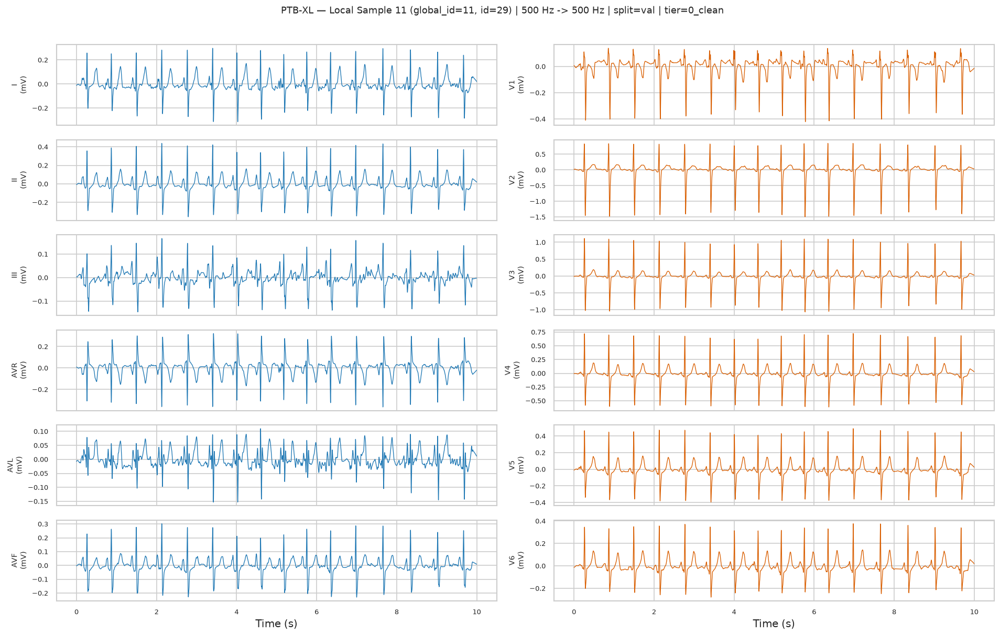

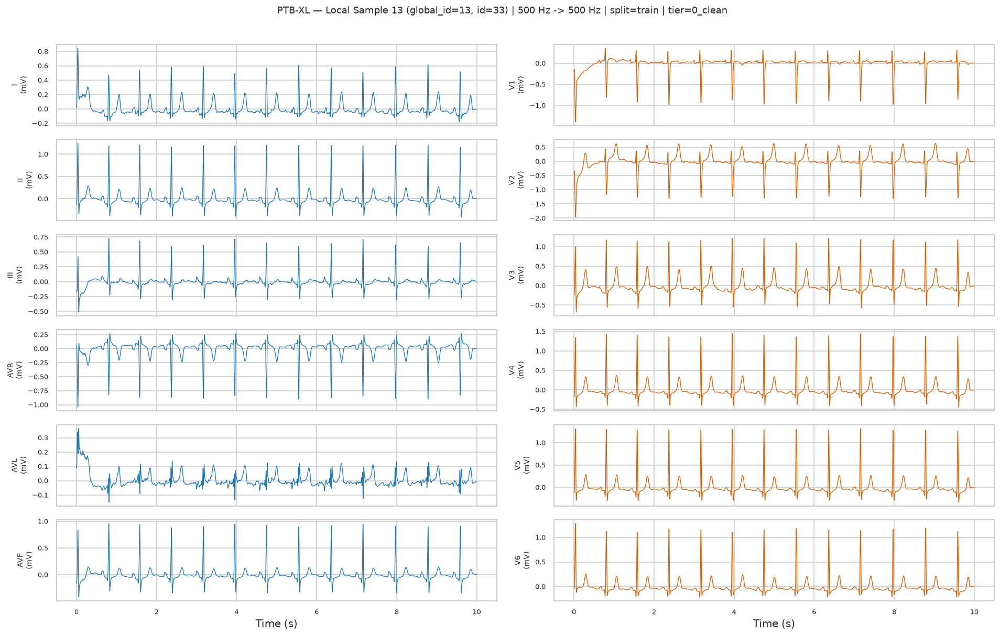

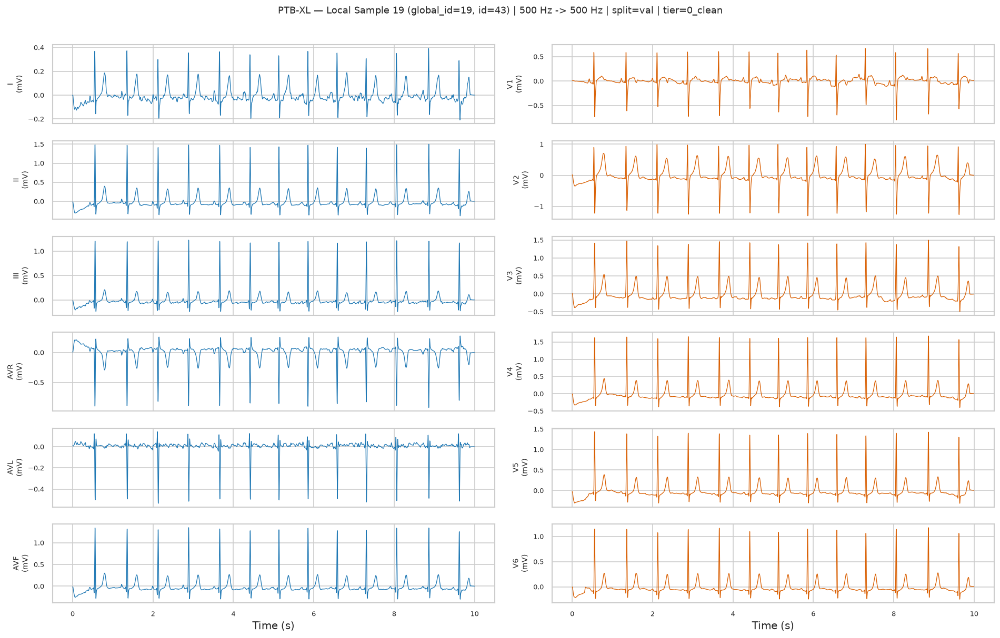

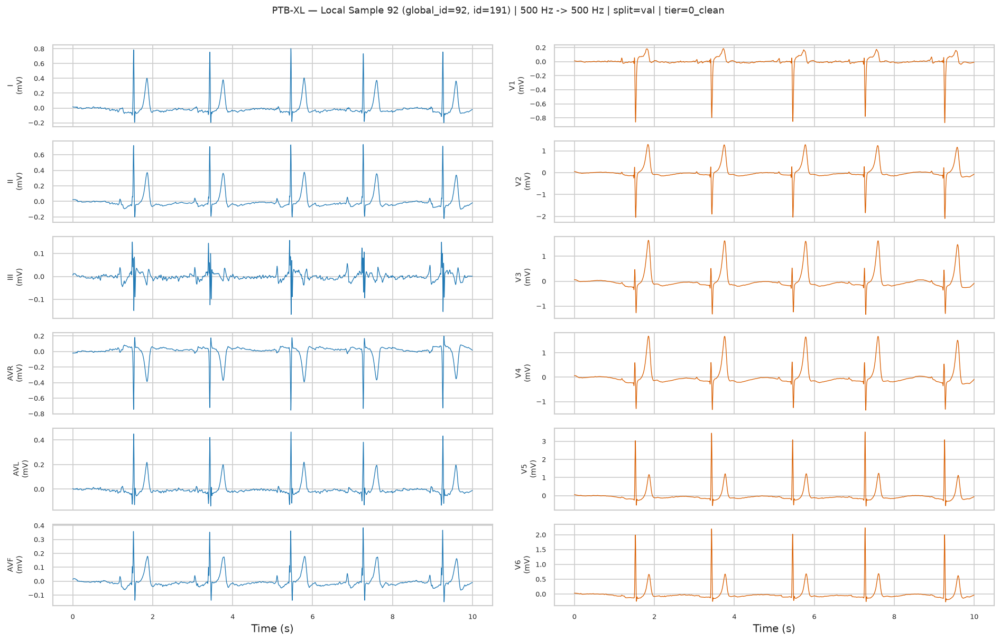

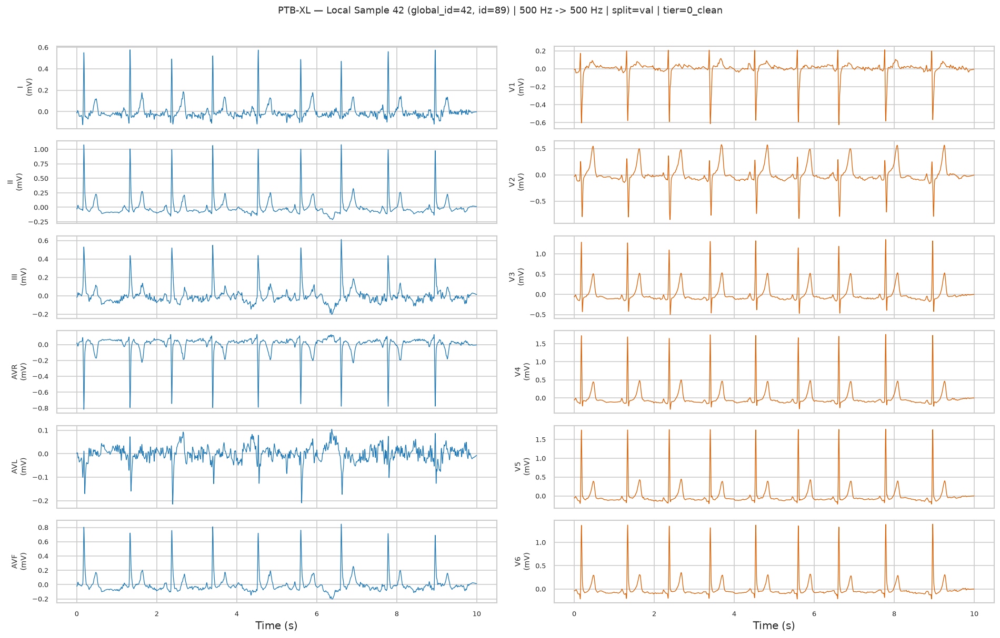

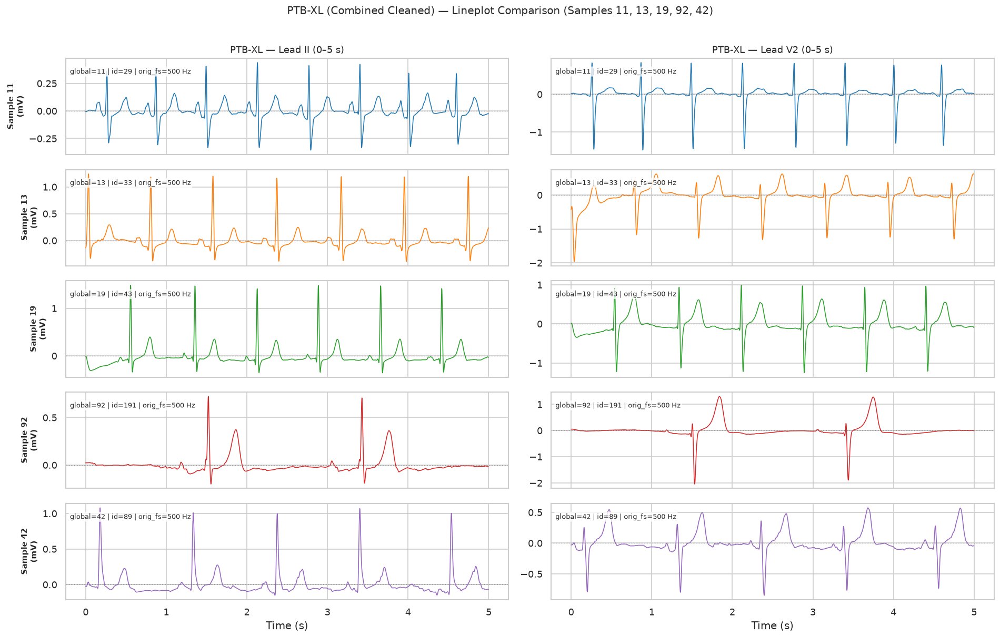

In [2]:
plot_source_samples("ptbxl", "PTB-XL")

## 2. MIMIC-IV-ECG (`sources=["mimic_iv_ecg"]`) — Samples `[11, 13, 19, 92, 42]`

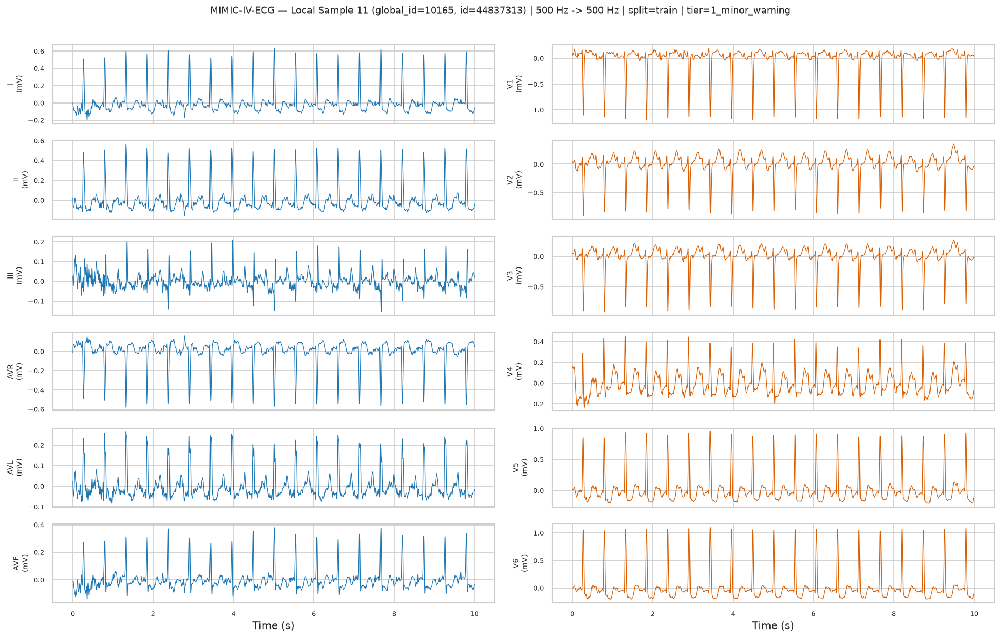

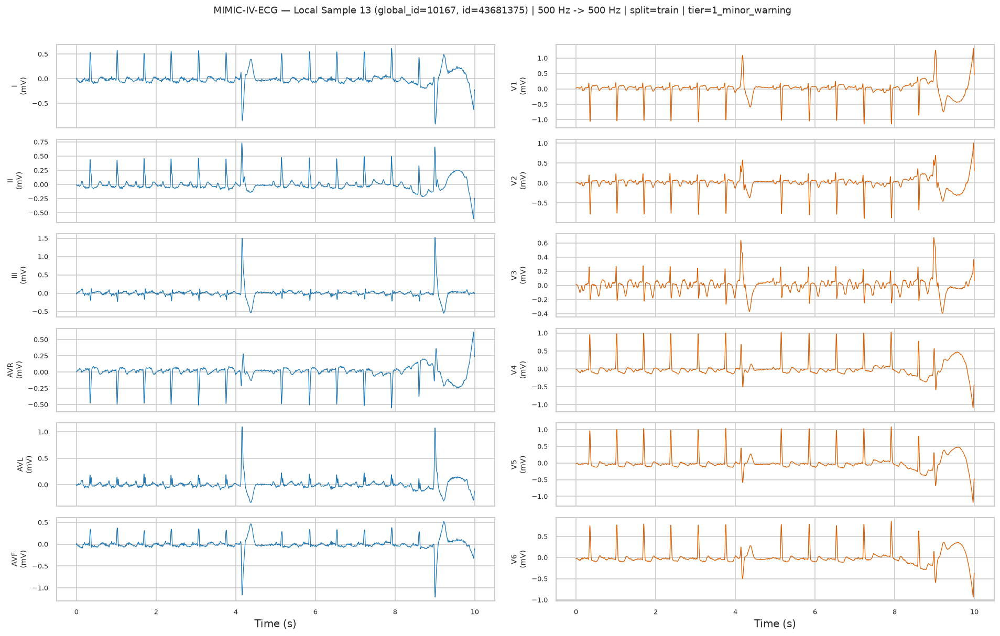

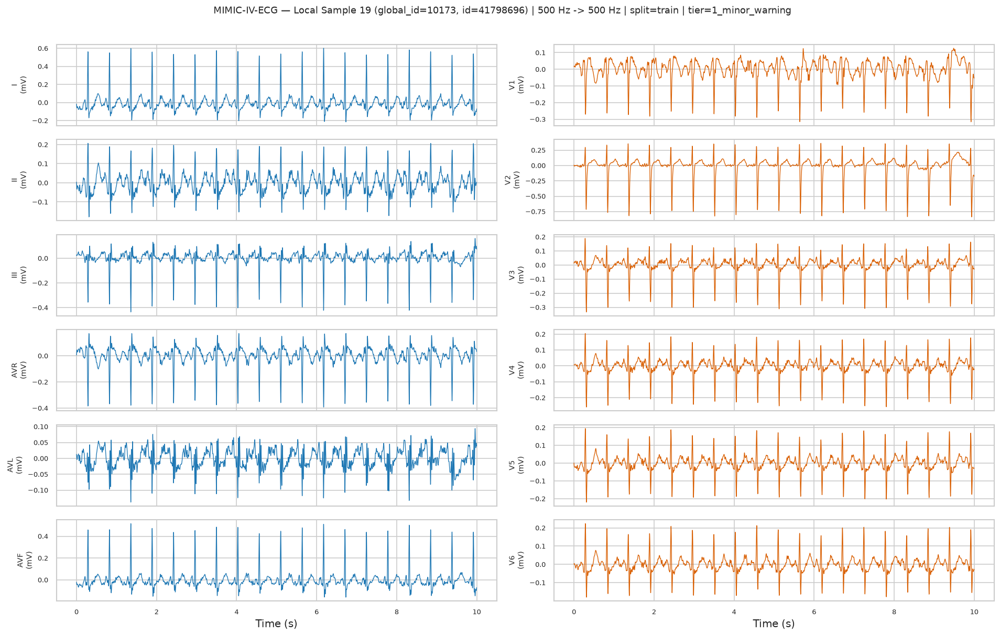

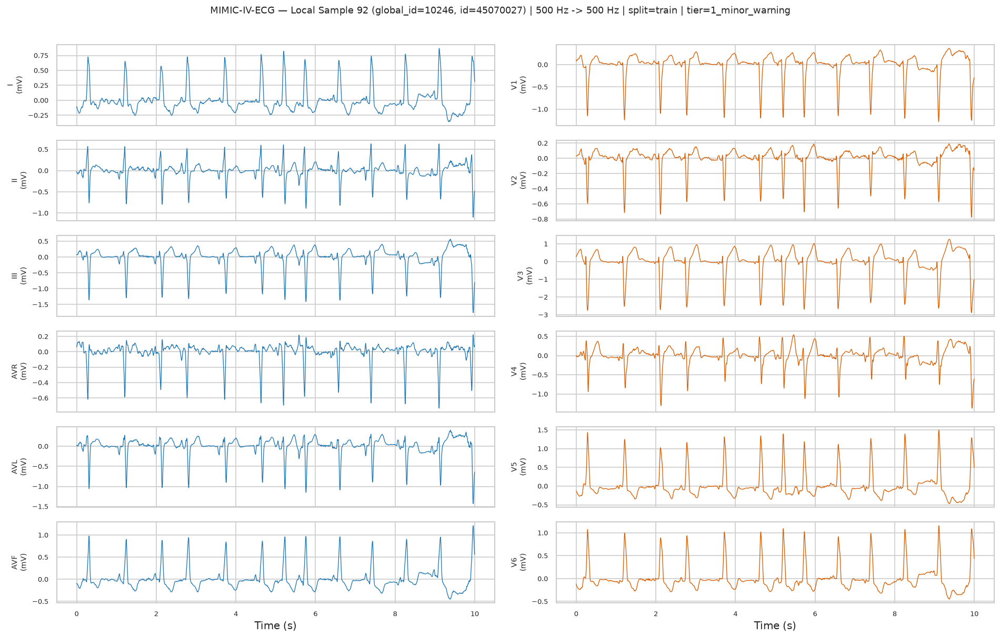

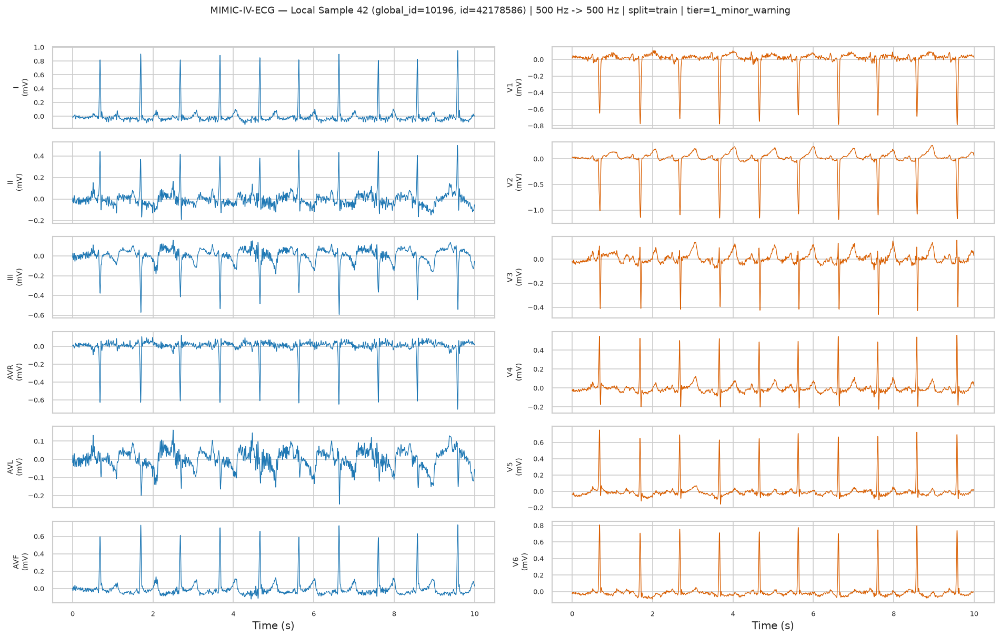

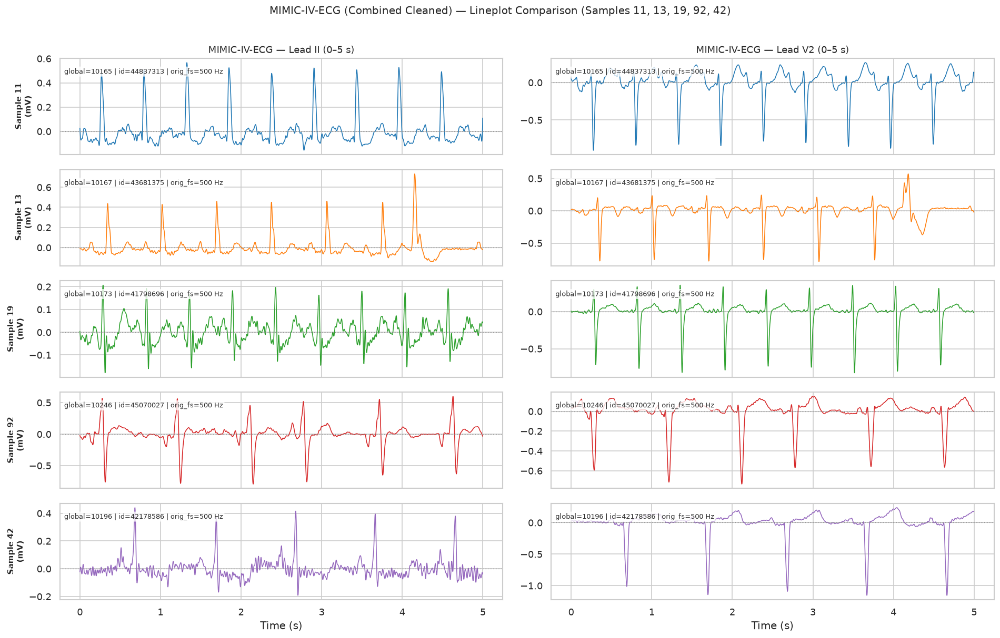

In [3]:
plot_source_samples("mimic_iv_ecg", "MIMIC-IV-ECG")

## 3. Georgia 12-Lead ECG (`sources=["georgia_ecg"]`) — Samples `[11, 13, 19, 92, 42]`

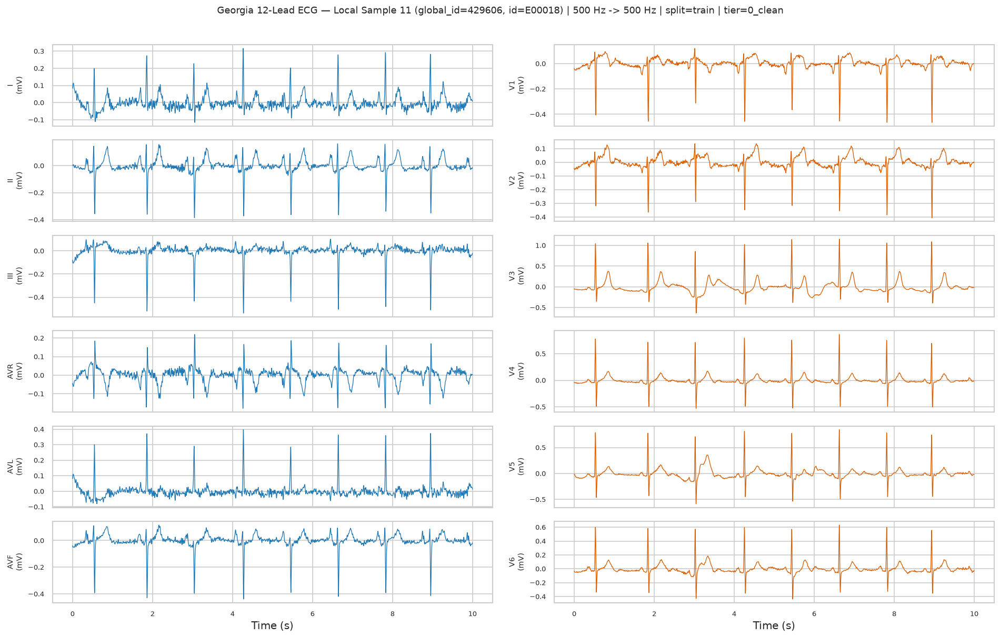

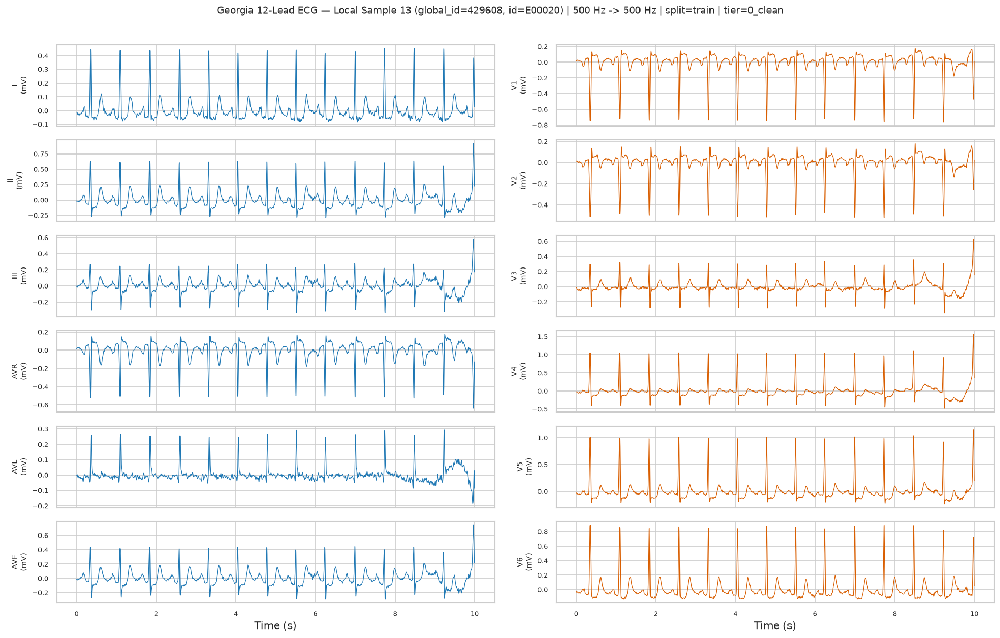

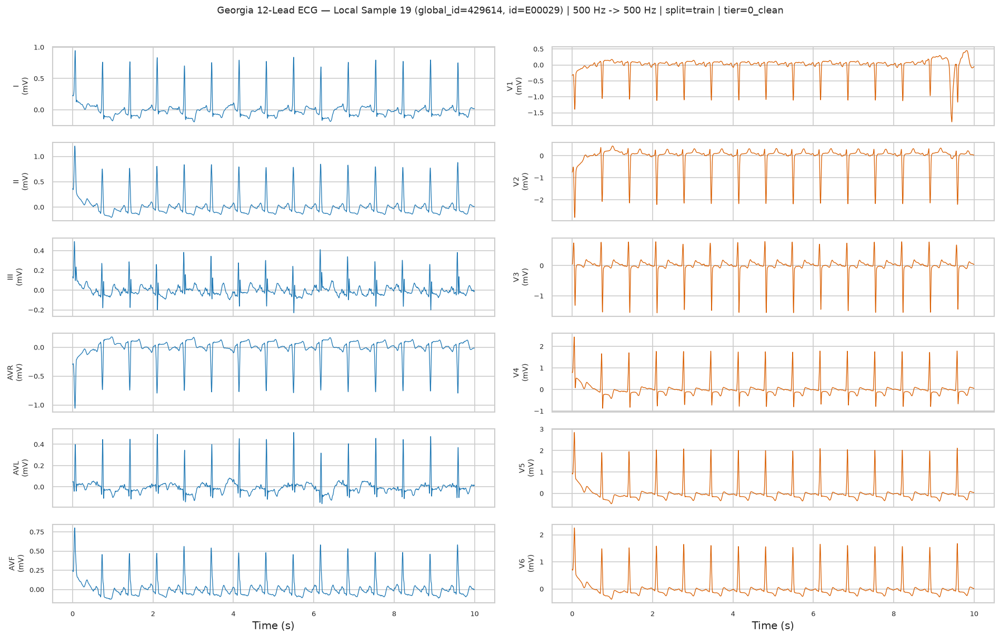

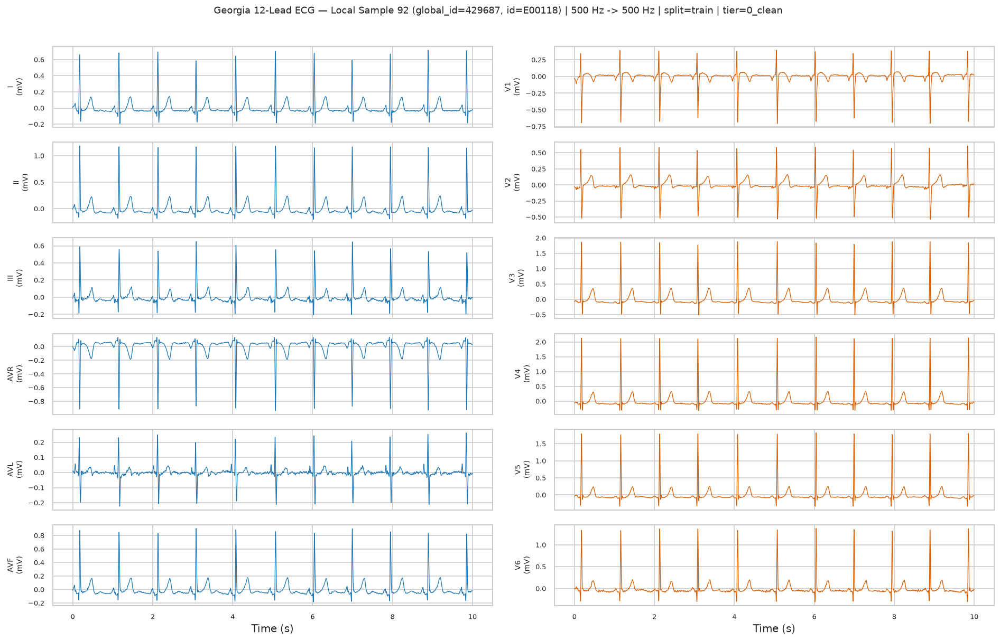

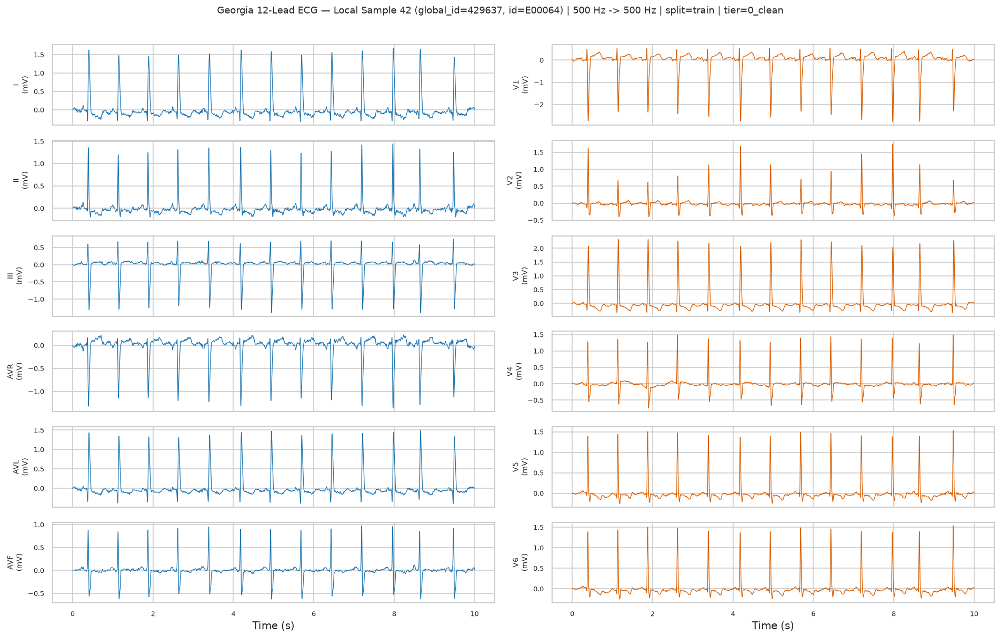

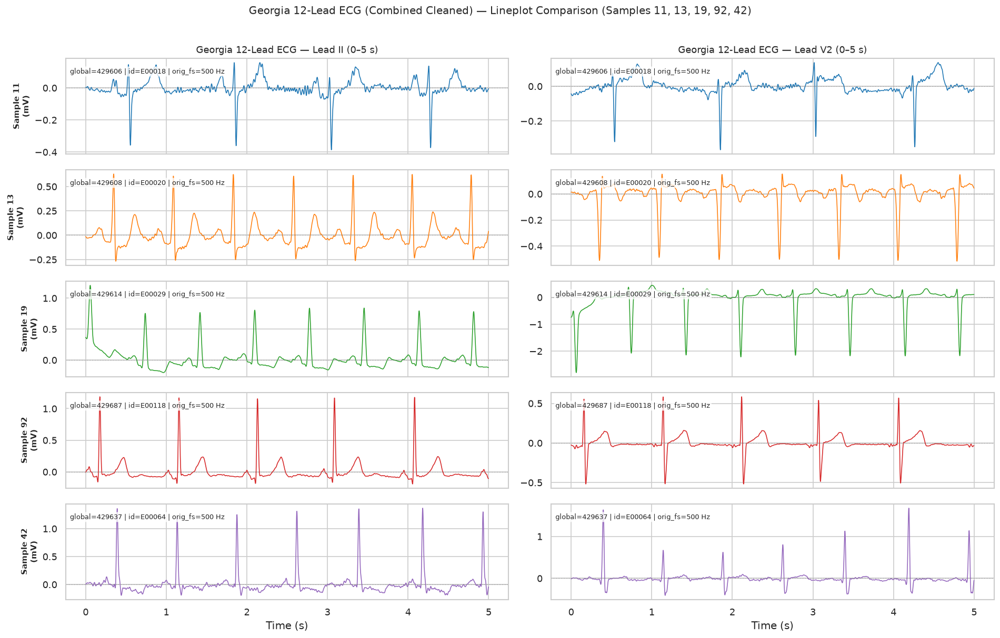

In [4]:
plot_source_samples("georgia_ecg", "Georgia 12-Lead ECG")

## 4. Chapman-Shaoxing (`sources=["chapman_shaoxing"]`) — Samples `[11, 13, 19, 92, 42]`

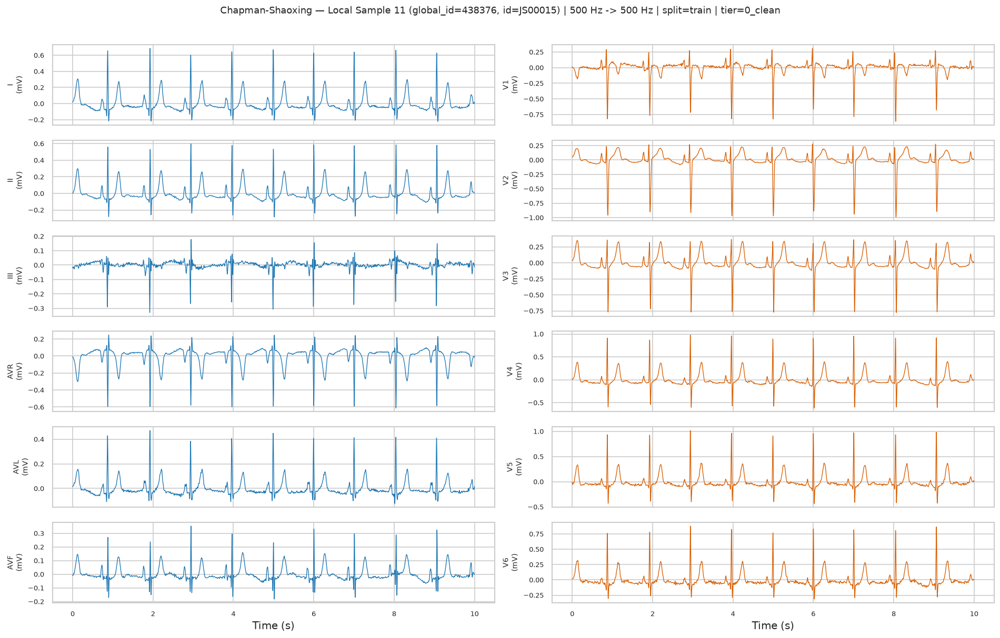

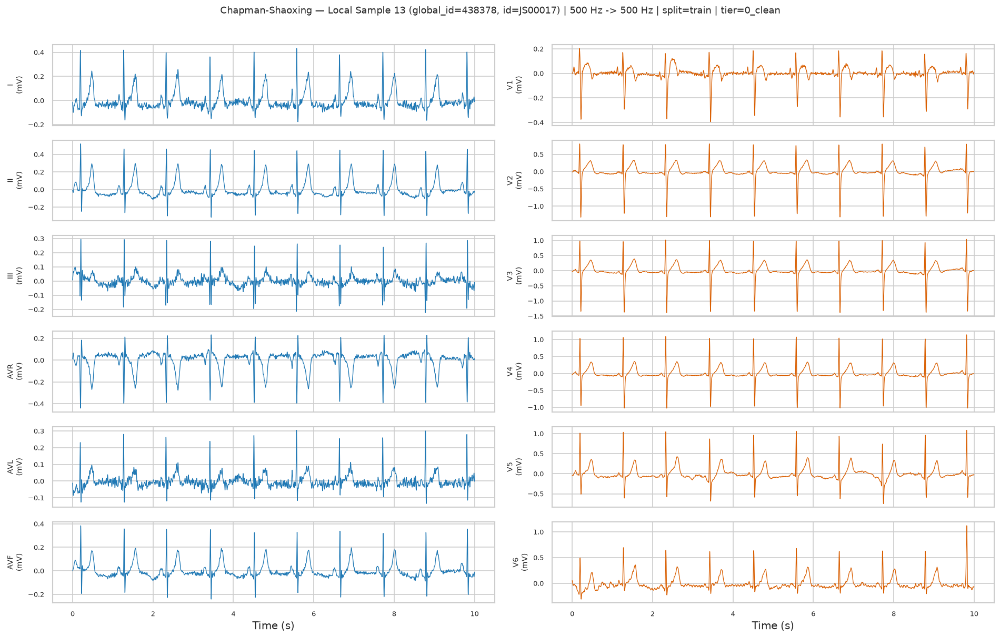

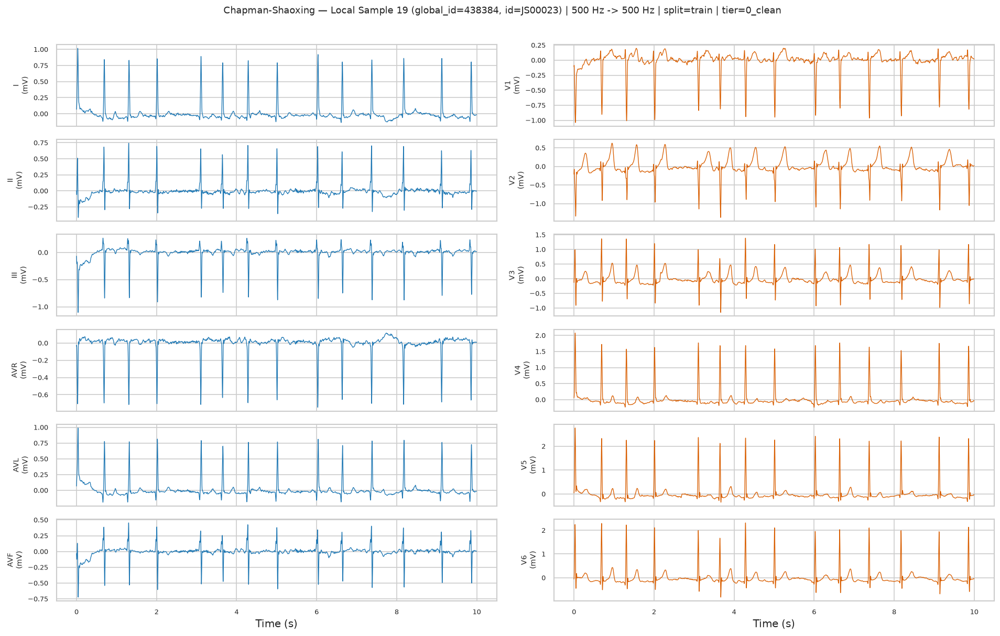

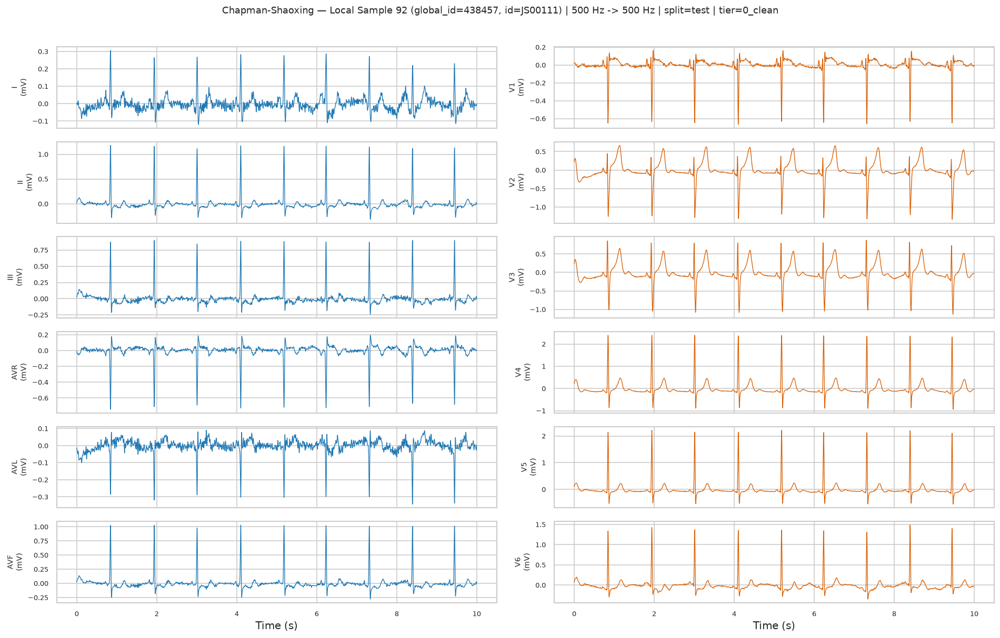

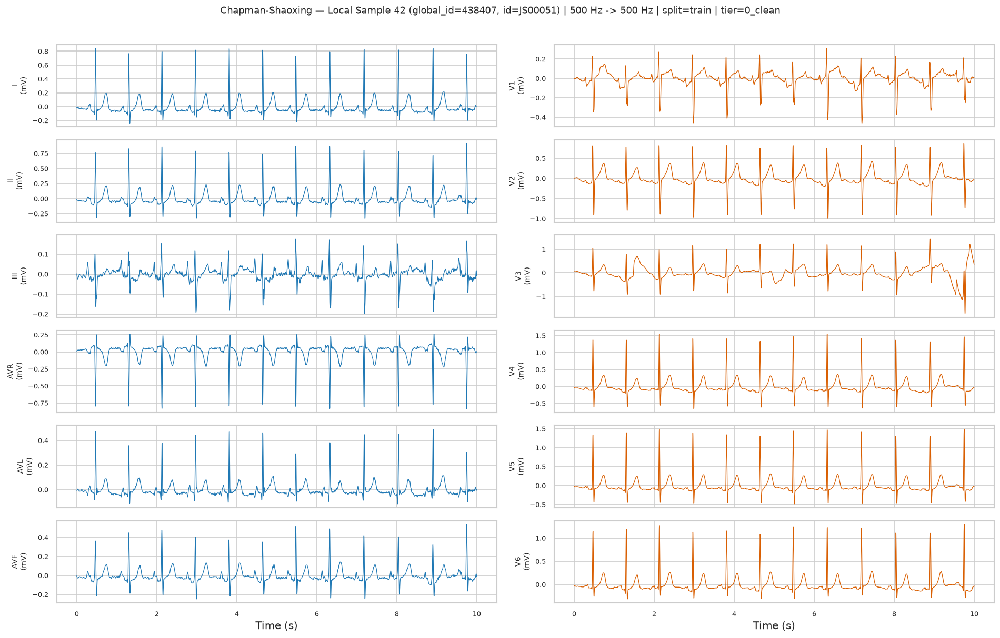

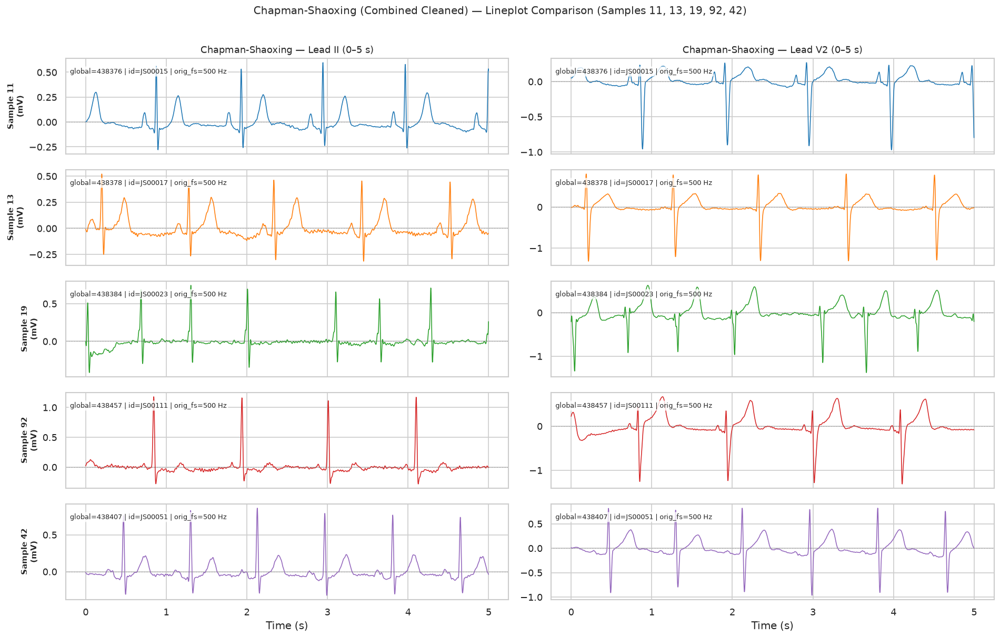

In [5]:
plot_source_samples("chapman_shaoxing", "Chapman-Shaoxing")

## 5. CODE-15% (`sources=["code15"]`) — Samples `[11, 13, 19, 92, 42]`

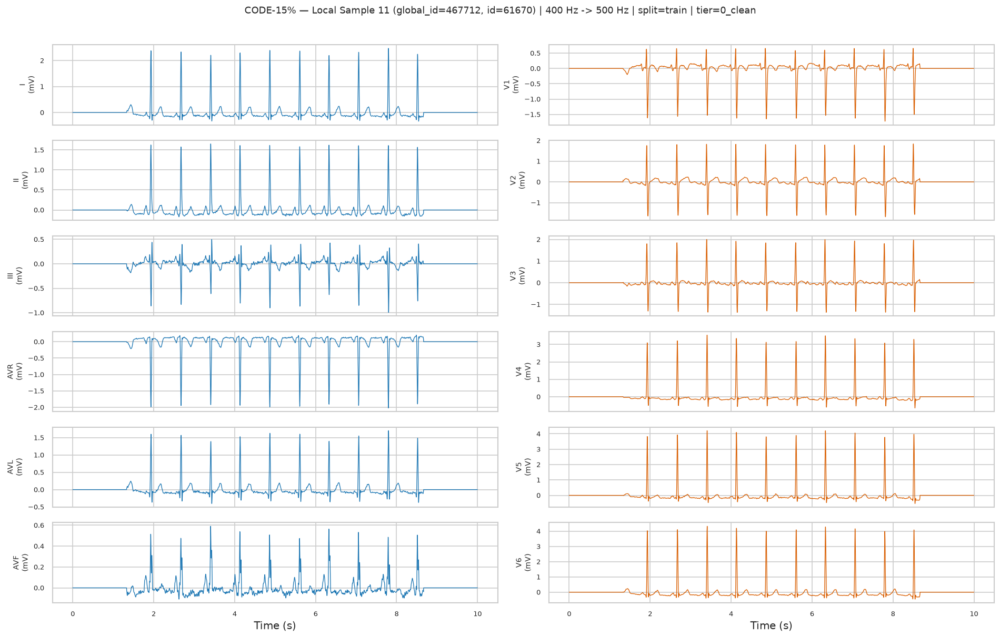

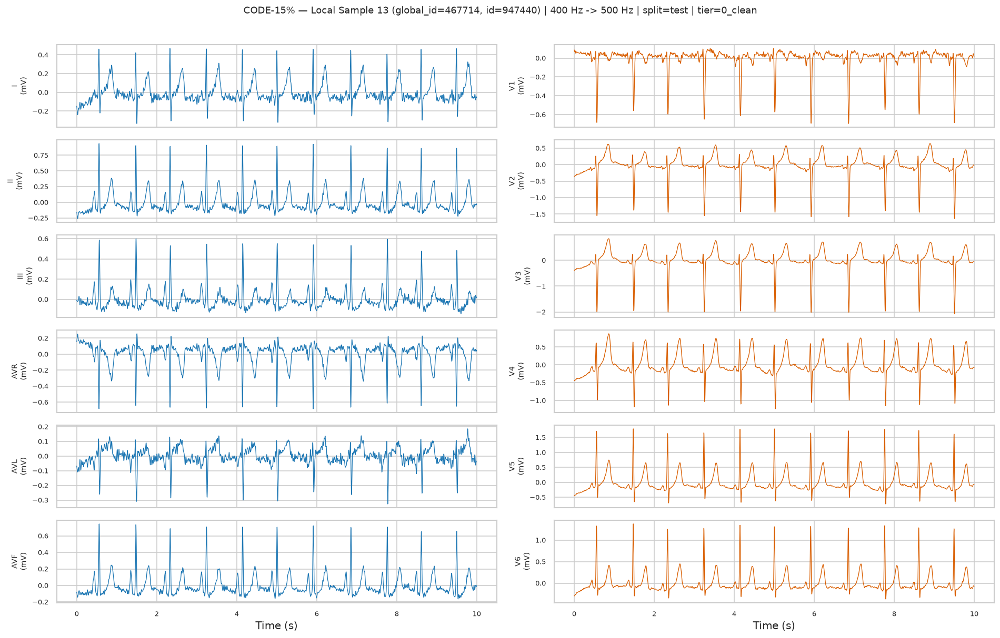

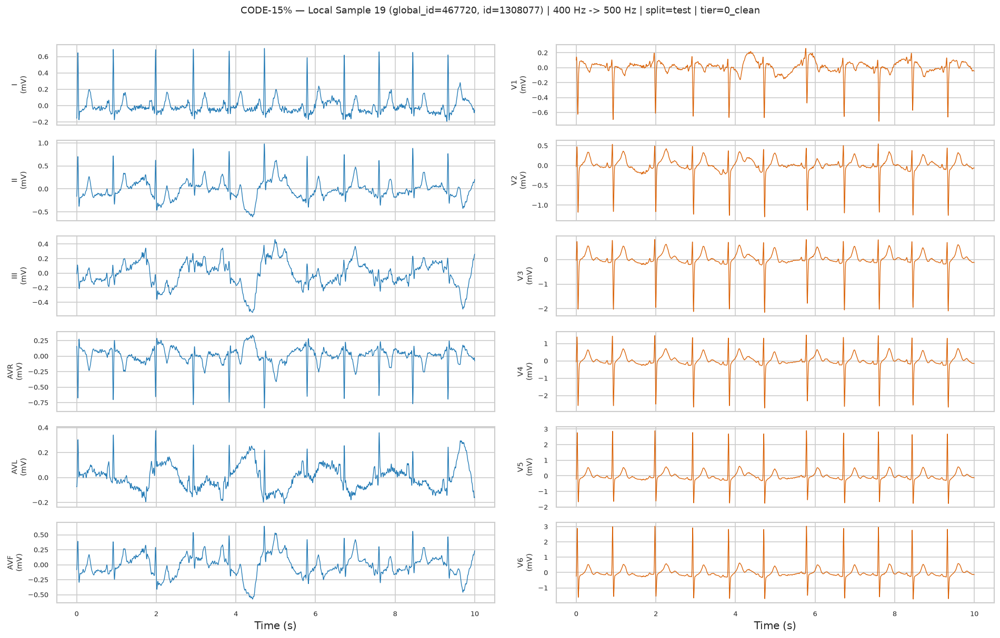

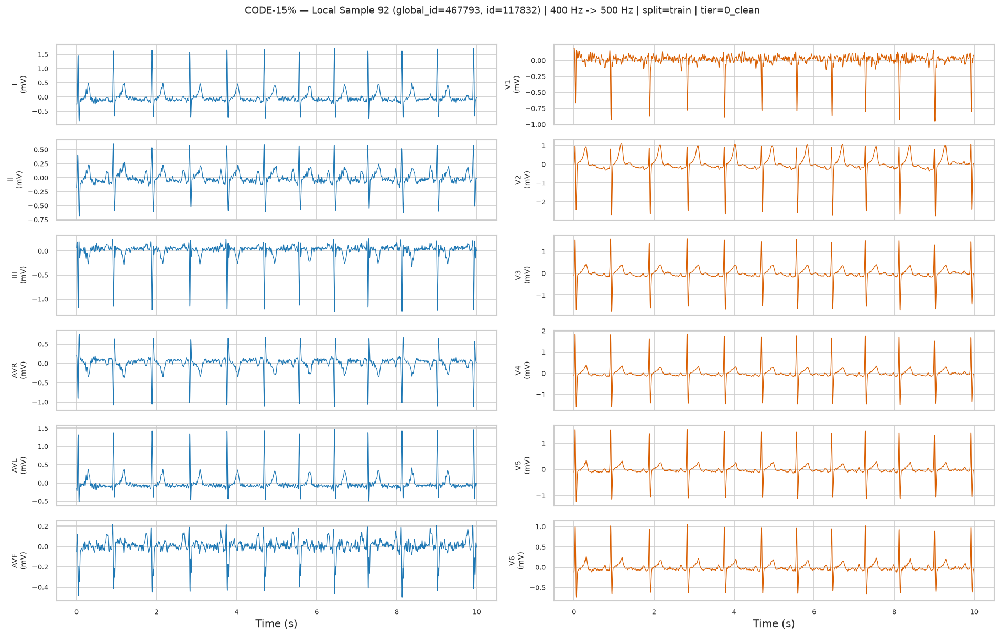

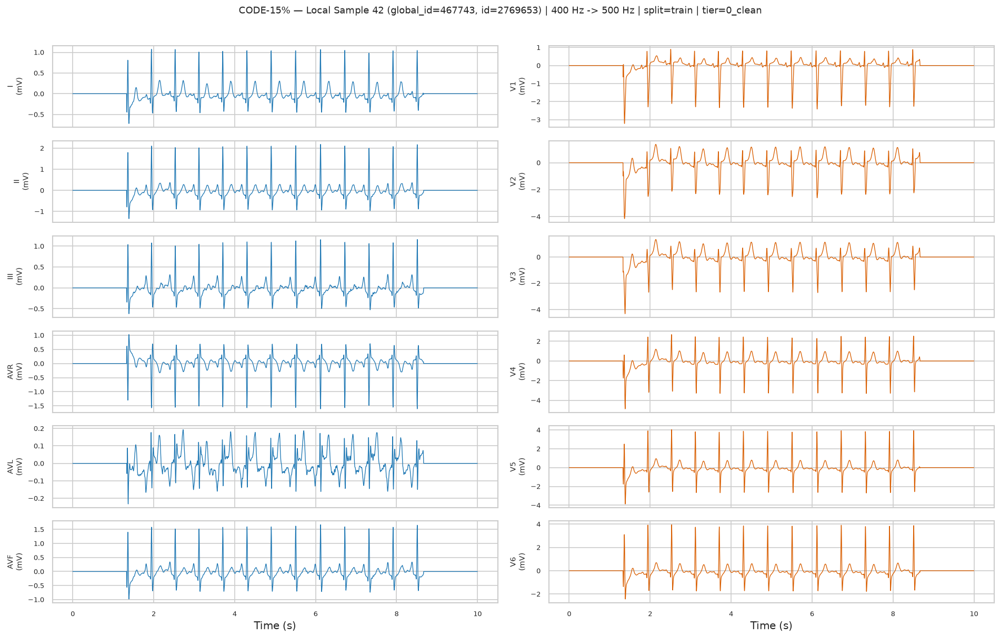

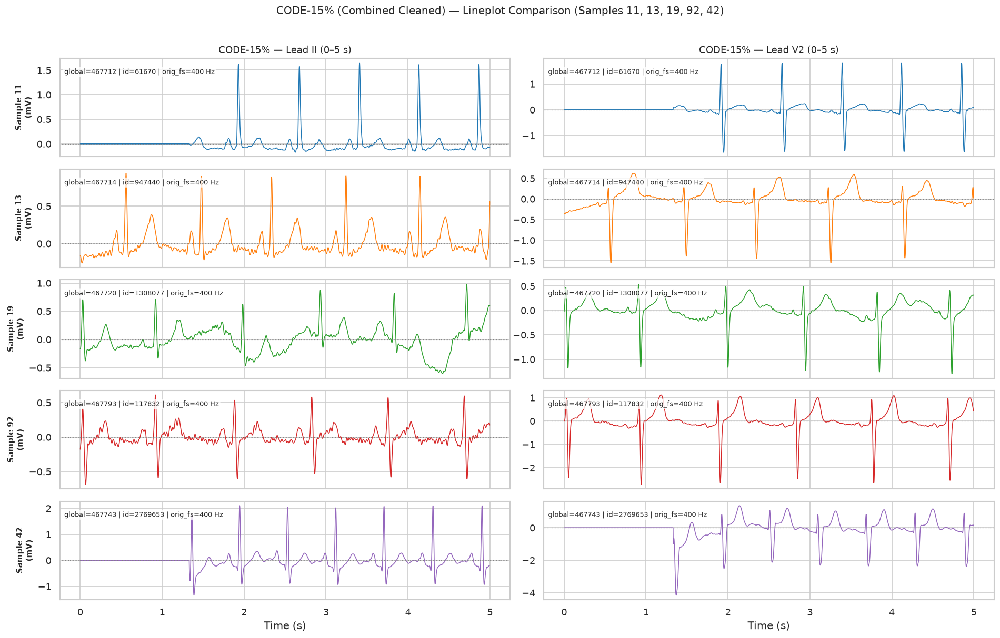

In [6]:
plot_source_samples("code15", "CODE-15%")